# Clasificando texto: predicción de `cod_final`

Cada registro describe un empleo con tres textos libres (`actividad`, `oficio`, `tareas`) y un código de dos dígitos (`cod_final`). Los códigos corresponden a la **actividad económica** del establecimiento: por ejemplo, `01` es agricultura y `84` es administración pública.

**Plan:**

1. Descargar `train` desde MySQL.
2. Explorar y preparar los datos.
3. Entrenar dos variantes de un mismo modelo y elegir una con un conjunto de validación.
4. Descargar `test` y predecir.
5. Analizar fortalezas y debilidades.
6. Proponer un plan de mejora.

La consigna pide no optimizar el resultado, así que buscamos un modelo **simple, rápido y razonable**.

**Puertas de validación (*gates*).** En cada etapa verificamos explícitamente los supuestos de los que depende el resto del análisis: cantidad de filas, ids únicos, formato de etiquetas, etc. Si un supuesto falla, el notebook se detiene con un mensaje claro en vez de producir resultados silenciosamente erróneos.

In [41]:
import time

import matplotlib.pyplot as plt
import mysql.connector
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

SEED = 42
TEXT_COLUMNS = ["actividad", "oficio", "tareas"]
COLUMNAS = ["id", *TEXT_COLUMNS, "cod_final"]

In [42]:
def gate(condicion: bool, mensaje: str) -> None:
    """Puerta de validación: detiene el notebook si un supuesto no se cumple."""
    if not condicion:
        raise AssertionError(f"GATE FALLIDO: {mensaje}")
    print(f"OK  {mensaje}")

## 1. Descarga de `train`

Un `SELECT * FROM train` completo excede el tiempo máximo de ejecución que permite el servidor (error 3024). Por eso descargamos la tabla **por bloques de `id`**: cada consulta es corta y el resultado final es el mismo. Además, comparamos el número de filas descargadas con un `COUNT(*)` hecho en la base de datos, para asegurarnos de que no se perdió ningún bloque.

In [43]:
DB = dict(
    host="sql.freedb.tech",
    port=3306,
    user="u_y8tlWZ",
    password="wSkxw3xbhsQg",
    database="freedb_N4nnid0a",
)


def conectar(reintentos: int = 6):
    """La BD es compartida y limita las conexiones simultáneas: reintentamos con espera creciente."""
    for intento in range(1, reintentos + 1):
        try:
            return mysql.connector.connect(**DB)
        except mysql.connector.Error as e:
            if intento == reintentos:
                raise
            print(
                f"Conexión rechazada ({e.msg}); reintento {intento} en {5 * intento}s"
            )
            time.sleep(5 * intento)

In [ ]:
df_train = pd.read_sql("SELECT * FROM `freedb_N4nnid0a`.`train`", con=conectar())

/tmp/ipykernel_104643/2527610669.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_train = pd.read_sql(


DatabaseError: 3024 (HY000): Query execution was interrupted, maximum statement execution time exceeded

In [ ]:
df_train.to_parquet("train.parquet", index=False)

In [ ]:
df_test = pd.read_sql("SELECT * FROM `freedb_N4nnid0a`.`test`", con=conectar())

/tmp/ipykernel_104643/2762625532.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql(


In [ ]:
df_test.to_parquet("test.parquet", index=False)

## 2. Exploración breve

Revisamos tres aspectos que condicionan la elección del modelo:

- **Distribución de clases:** ¿están balanceadas?
- **Largo y calidad de los textos:** ¿son frases largas o descripciones cortas?
- **Duplicados contradictorios:** ¿hay un mismo texto con etiquetas distintas?

Clases distintas: 79
Clase más frecuente: 48 (5,507 registros, 15.6%)
Clases con menos de 30 ejemplos: 14


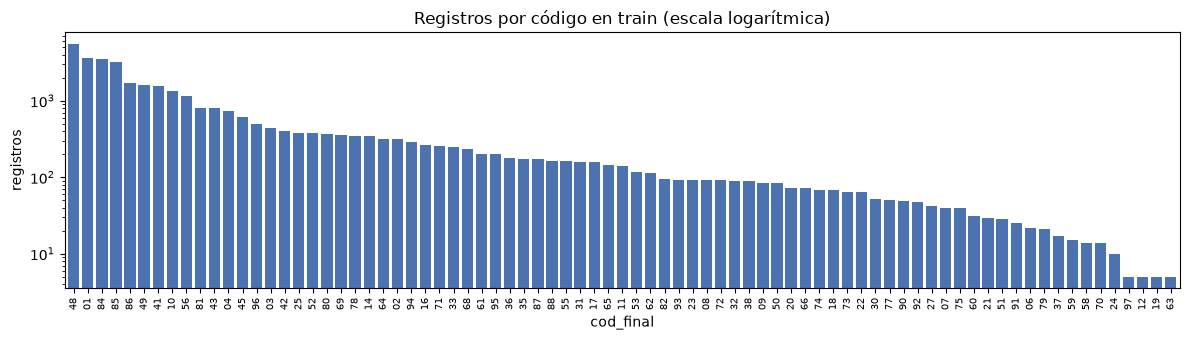

In [ ]:
conteo = df_train["cod_final"].value_counts()
print(f"Clases distintas: {conteo.size}")
print(
    f"Clase más frecuente: {conteo.index[0]} ({conteo.iloc[0]:,} registros, {conteo.iloc[0] / len(train):.1%})"
)
print(f"Clases con menos de 30 ejemplos: {(conteo < 30).sum()}")

fig, ax = plt.subplots(figsize=(12, 3.5))
conteo.plot.bar(ax=ax, color="#4C72B0", width=0.8)
ax.set_yscale("log")
ax.set_title("Registros por código en train (escala logarítmica)")
ax.set_xlabel("cod_final")
ax.set_ylabel("registros")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()

In [ ]:
largos = pd.DataFrame(
    {c: df_train[c].str.split().str.len() for c in TEXT_COLUMNS},
)
vacios = (
    (df_train[TEXT_COLUMNS].apply(lambda s: s.str.strip() == "")).sum().rename("vacíos")
)

pd.concat([largos.describe().T[["mean", "50%", "max"]].round(1), vacios], axis=1)

NameError: name 'TEXT_COLUMNS' is not defined

In [ ]:
dup = df_train.groupby(TEXT_COLUMNS)["cod_final"].nunique()
print(f"Textos idénticos repetidos: {df_train.duplicated(TEXT_COLUMNS).sum()}")
print(f"Textos idénticos con etiquetas distintas: {(dup > 1).sum()}")
df_train.set_index(TEXT_COLUMNS).loc[dup[dup > 1].index[:3]].reset_index()

Textos idénticos repetidos: 426
Textos idénticos con etiquetas distintas: 9


,actividad,oficio,tareas,id,cod_final
0,CARPINTERÍA,,,39486,41
1,CARPINTERÍA,,,39572,41
2,CARPINTERÍA,,,39690,41
3,CARPINTERÍA,,,39741,41
4,CARPINTERÍA,,,39928,41
5,CARPINTERÍA,,,39929,41
6,CARPINTERÍA,,,39940,31
7,COMERCIANTE,,,39439,22
8,COMERCIANTE,,,39716,56
9,COMERCIANTE,,,39720,56


**Qué nos dice la exploración:**

- **Desbalance fuerte.** Hay 79 clases. La más grande tiene más de 5.000 ejemplos y algunas tienen solo 5. Por eso no basta con mirar la *accuracy*: también usaremos el **F1 macro**, que da el mismo peso a cada clase.
- **Textos cortos.** Cada campo tiene típicamente 3 a 6 palabras, con errores de tipeo (*"cultivo dd frambuesas"*), abreviaciones y tildes inconsistentes. No hay un contexto largo que un modelo de lenguaje pueda aprovechar.
- **Un poco de ruido en las etiquetas.** Unos pocos textos idénticos tienen códigos distintos. Es algo esperable en codificación manual: lo dejamos como está y lo tratamos como una cota al desempeño alcanzable.



## 3. Preparación y modelo

**Representación.** Usamos TF-IDF sobre **n-gramas de caracteres** (2 a 5 caracteres) y lo calculamos **por separado para cada campo**:

- Los n-gramas de caracteres toleran errores de tipeo y variaciones morfológicas: *"agrícola"*, *"agricola"* y *"agricultura"* comparten muchos fragmentos.
- Separar los campos mantiene su identidad. *"Conductor"* en `oficio` no significa lo mismo que en `actividad`, y para un código de actividad económica el campo `actividad` probablemente pesa más que los demás.
- La normalización es mínima: minúsculas y eliminación de tildes (`strip_accents`). No quitamos *stopwords*, porque en textos tan cortos cada palabra aporta.

**Clasificador.** Usamos una SVM lineal (`LinearSVC`). Es el estándar para clasificación de texto con TF-IDF: entrena en segundos con decenas de miles de registros y cientos de miles de atributos, y suele quedar muy cerca de modelos bastante más costosos.

**Dos variantes.** Comparamos el modelo sin ponderar contra uno con `class_weight="balanced"`, que penaliza más los errores en clases poco frecuentes. Para no usar `test` en la decisión, separamos el 20% de `train` como **validación**, estratificado por clase.

**Regla de decisión (fijada antes de ver resultados).** Elegimos por *accuracy*, porque representa la fracción de registros que el modelo codifica bien, es decir, el trabajo manual que ahorra. Si la diferencia en *accuracy* es menor a 0,5 puntos, desempatamos por F1 macro.

In [ ]:
def make_model(class_weight=None) -> Pipeline:
    def tfidf():
        return TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(2, 5),
            sublinear_tf=True,
            min_df=2,
            strip_accents="unicode",
            lowercase=True,
        )

    columns = ColumnTransformer(
        [(c, tfidf(), c) for c in TEXT_COLUMNS],
    )
    return Pipeline(
        [
            ("tfidf", columns),
            ("svm", LinearSVC(C=0.5, class_weight=class_weight)),
        ]
    )


def prepare_data(df: pd.DataFrame) -> pd.DataFrame:
    """Normalización mínima: sin nulos y con espacios colapsados."""
    return (
        df[TEXT_COLUMNS]
        .fillna("")
        .apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))
    )


X, y = prepare_data(df_train), df_train["cod_final"]
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
gate(
    set(y_val) <= set(y_tr),
    "todas las clases de validación están presentes en entrenamiento",
)

OK  todas las clases de validación están presentes en entrenamiento


In [45]:
variantes = {
    "sin ponderar": None,
    "balanceado": "balanced",
}
filas = []

for nombre, cw in variantes.items():
    pred = make_model(cw).fit(X_tr, y_tr).predict(X_val)
    filas.append(
        {
            "modelo": nombre,
            "accuracy": accuracy_score(y_val, pred),
            "f1_macro": f1_score(y_val, pred, average="macro"),
        }
    )
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.round(3)

,accuracy,f1_macro
modelo,,
sin ponderar,0.913,0.754
balanceado,0.911,0.765


In [46]:
a, b = comparacion.loc["sin ponderar"], comparacion.loc["balanceado"]
if abs(a["accuracy"] - b["accuracy"]) >= 0.005:
    elegido = comparacion["accuracy"].idxmax()
else:
    elegido = comparacion["f1_macro"].idxmax()
print(f"Modelo elegido: {elegido}")

modelo = make_model(variantes[elegido]).fit(X, y)  # reentrenamos con todo train

Modelo elegido: balanceado


**Resultado de la comparación.** Las dos variantes quedan prácticamente empatadas en *accuracy*: la diferencia es de unas décimas de punto, menos que el umbral de 0,5. Por la regla de desempate gana la versión **balanceada**, que mejora el F1 macro en alrededor de un punto. Es el resultado esperable: ponderar las clases poco frecuentes les ayuda un poco sin perjudicar casi nada a las grandes. Como la diferencia es pequeña y viene de una sola partición, no la consideramos concluyente. Lo importante es que la decisión se tomó con una regla fijada de antemano y sin mirar `test`.

## 4. Descarga de `test` y predicción

In [ ]:
gate(
    list(df_test.columns) == list(df_train.columns),
    "test tiene el mismo esquema que train",
)
gate(df_test["id"].is_unique, "los id de test son únicos")
gate(
    not set(df_test["id"]) & set(df_train["id"]),
    "no hay registros compartidos entre train y test (sin fuga de datos)",
)
gate(
    df_test[TEXT_COLUMNS + ["cod_final"]].notna().all().all(),
    "no hay valores nulos en test",
)
nuevas = set(df_test["cod_final"]) - set(df_train["cod_final"])
gate(
    not nuevas,
    f"todas las etiquetas de test fueron vistas en train (nuevas: {sorted(nuevas)})",
)

OK  test tiene el mismo esquema que train
OK  los id de test son únicos
OK  no hay registros compartidos entre train y test (sin fuga de datos)
OK  no hay valores nulos en test
OK  todas las etiquetas de test fueron vistas en train (nuevas: [])


In [ ]:
df_test["pred"] = modelo.predict(prepare_data(df_test))
margenes = modelo.decision_function(prepare_data(df_test))
df_test["confianza"] = np.sort(margenes, axis=1)[:, -1]  # puntaje de la clase ganadora

gate(
    set(df_test["pred"]) <= set(df_train["cod_final"]),
    "todas las predicciones son códigos válidos",
)

OK  todas las predicciones son códigos válidos


## 5. Análisis de resultados

### 5.1 Métricas globales

Para tener un punto de referencia, incluimos un modelo trivial que siempre predice la clase más frecuente.

In [ ]:
# use dummy classifier to compare with baseline
from sklearn.dummy import DummyClassifier

dummy_classifier = DummyClassifier(strategy="most_frequent")
dummy_classifier.fit(X, y)
df_test["pred_dummy"] = dummy_classifier.predict(prepare_data(df_test))

In [54]:
df_test.head()

,id,actividad,oficio,tareas,cod_final,pred,confianza,pred_dummy
0,21480,investigacion y desarrollo de semillas de toma...,encargado de riego,"abrir y cerrar flujos de agua, revisar riegos",72,72,0.389137,48
1,16064,metro de santiago,mantencion en metro,realiza mantencion a tableros eléctricos y bom...,49,49,-0.684760,48
2,12589,"producción de uva vinifera (solo produccion), ...",temporero agricola,poda de uva vinifera en forma manual con tijer...,01,01,0.958511,48
3,9547,comercio de decoración para el hogar,vendedora de local decoración,"atención de público, recibe dinero, da vuelto,...",48,48,-0.280737,48
4,19225,jardín infantil,auxiliar de aseo en jardín infantil,asear instalaciones,85,85,0.711345,48


In [ ]:
metricas = pd.Series(
    {
        "accuracy": accuracy_score(
            df_test["cod_final"],
            df_test["pred"],
        ),
        "f1_macro": f1_score(
            df_test["cod_final"],
            df_test["pred"],
            average="macro",
        ),
        "f1_ponderado": f1_score(
            df_test["cod_final"],
            df_test["pred"],
            average="weighted",
        ),
        "accuracy_clase_mayoritaria": accuracy_score(
            df_test["cod_final"], df_test["pred_dummy"]
        ),
    }
).round(3)
gate(
    metricas["accuracy"] > metricas["accuracy_clase_mayoritaria"],
    "el modelo supera al baseline trivial",
)
metricas.to_frame("test")

OK  el modelo supera al baseline trivial


,test
accuracy,0.912
f1_macro,0.778
f1_ponderado,0.912
accuracy_clase_mayoritaria,0.156


### 5.2 Desempeño por clase

In [ ]:
reporte = (
    pd.DataFrame(
        classification_report(
            df_test["cod_final"],
            df_test["pred"],
            output_dict=True,
            zero_division=0,
        )
    )
    .T.drop(index=["accuracy", "macro avg", "weighted avg"])
    .assign(soporte_train=conteo)
    .rename(columns={"support": "soporte_test"})
)
reporte["soporte_test"] = reporte["soporte_test"].astype(int)
reporte = reporte.round(3).sort_values("f1-score")
print("Las 10 clases con peor F1:")
reporte.head(10)

Las 10 clases con peor F1:


,precision,recall,f1-score,soporte_test,soporte_train
19,0.000,0.0,0.000,1,5
27,0.000,0.0,0.000,5,42
70,0.000,0.0,0.000,1,14
59,0.000,0.0,0.000,2,15
32,0.500,0.3,0.375,10,90
09,0.444,0.4,0.421,10,85
07,1.000,0.4,0.571,5,40
72,0.545,0.6,0.571,10,91
74,0.667,0.5,0.571,8,68
90,0.600,0.6,0.600,5,49


Correlación de Spearman (ejemplos vs F1): 0.51


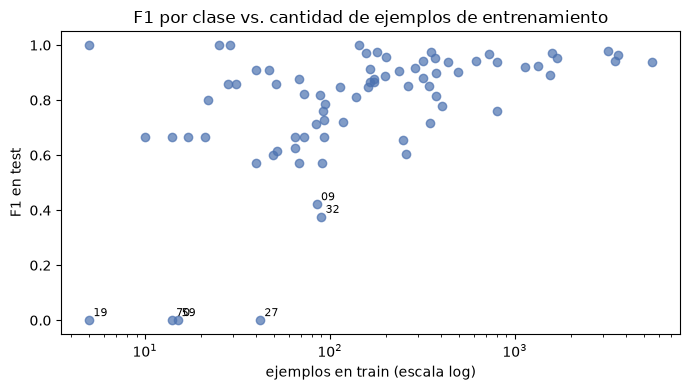

In [57]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(reporte["soporte_train"], reporte["f1-score"], color="#4C72B0", alpha=0.7)
ax.set_xscale("log")
ax.set_xlabel("ejemplos en train (escala log)")
ax.set_ylabel("F1 en test")
ax.set_title("F1 por clase vs. cantidad de ejemplos de entrenamiento")
for cod, fila in reporte.head(6).iterrows():
    ax.annotate(
        cod,
        (fila["soporte_train"], fila["f1-score"]),
        fontsize=8,
        xytext=(3, 3),
        textcoords="offset points",
    )
plt.tight_layout()

print(
    f"Correlación de Spearman (ejemplos vs F1): {reporte['soporte_train'].corr(reporte['f1-score'], method='spearman'):.2f}"
)

### 5.3 ¿Qué clases se confunden?

In [58]:
errores = df_test[df_test["cod_final"] != df_test["pred"]]
(
    errores.groupby(["cod_final", "pred"])
    .size()
    .rename("n_errores")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

,cod_final,pred,n_errores
0,43,41,14
1,48,01,7
2,41,43,6
3,41,42,5
4,84,86,5
5,86,84,5
6,01,10,4
7,10,48,4
8,56,48,4
9,48,10,4


In [59]:
errores.sample(10, random_state=SEED)[TEXT_COLUMNS + ["cod_final", "pred"]]

,actividad,oficio,tareas,cod_final,pred
2259,VENTA DE HORTALIZAS FERIAS LIBRES Y HUEVOS EN ...,,,01,48
1768,cuidado y mantén de bosques nacionales,capataz de conaf,"supervisa trabajo en invernaderos., limpieza y...",84,02
2568,"confeccionar abecedarios, juegos didacticos de...",confecciona manualidades,"confecciona abecedario, juegos didácticos, par...",32,14
2372,barraca de madera de pino,operario en impregnado,carga e impregnado de madera de pino,48,16
3650,PIONETA,,,52,03
3801,importación de frutas,tractorista agrícola,realiza operaciones de siembra y plantación de...,48,01
3652,exportación de salmones,asistente administrativo,encargado de abastecimiento de alimentación a ...,48,03
3033,presta servicios de directora de arte a produc...,directora de arte,diseña espacios audiovisuales,90,59
1225,mantencion de parques,orillador,orillar con maquina en pasto y palzoletas,81,33
2539,venta de comida de perros y neumaticos.al deta...,dueño de una pime,admi istraciln de negocionde venta de comida d...,48,45


Durante la exploración vimos que hay registros donde **solo viene `actividad`**, escrita en mayúsculas y con `oficio` y `tareas` vacíos. Parecen provenir de otro formato de captura. ¿Cómo le va al modelo con ellos?

In [60]:
df_test["registro_completo"] = (
    df_test[["oficio", "tareas"]].apply(lambda s: s.str.strip() != "").all(axis=1)
)
df_test.assign(acierto=df_test["cod_final"] == df_test["pred"]).groupby(
    "registro_completo"
)["acierto"].agg(accuracy="mean", registros="size").round(3)

,accuracy,registros
registro_completo,,
False,0.674,46
True,0.915,3881


### 5.4 ¿Sabe el modelo cuándo se equivoca?

Si el puntaje de la clase ganadora (`confianza`) separa bien aciertos de errores, el modelo se puede usar en un esquema **mixto**: los casos de alta confianza se codifican automáticamente y los de baja confianza se derivan a un codificador humano. Dividimos test en cinco grupos del mismo tamaño según su confianza.

In [61]:
df_test["quintil_confianza"] = pd.qcut(
    df_test["confianza"], 5, labels=["Q1 (baja)", "Q2", "Q3", "Q4", "Q5 (alta)"]
)
df_test["acierto"] = df_test["cod_final"] == df_test["pred"]
df_test.groupby("quintil_confianza", observed=True)["acierto"].agg(
    accuracy="mean", registros="size"
).round(3)

,accuracy,registros
quintil_confianza,,
Q1 (baja),0.690,786
Q2,0.912,785
Q3,0.973,785
Q4,0.991,785
Q5 (alta),0.995,786


In [64]:
# Si se automatiza solo el X% más confiable y el resto va a revisión humana:
orden = df_test.sort_values(
    "confianza",
    ascending=False,
)["acierto"].to_numpy()

# Se calcula la cobertura y la accuracy de los registros automatizados para distintos percentiles de confianza
cobertura = pd.DataFrame(
    {
        "automatizado": [f"{p:.0%}" for p in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0)],
        "accuracy_en_automatizados": [
            orden[: int(p * len(orden))].mean() for p in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0)
        ],
    }
).round(3)
cobertura

,automatizado,accuracy_en_automatizados
0,50%,0.991
1,60%,0.986
2,70%,0.980
3,80%,0.968
4,90%,0.947
5,100%,0.912


### 5.5 Fortalezas y espacios de mejora

**Fortalezas**

- **Buen desempeño con un modelo muy simple.** Una *accuracy* cercana a 0,91, frente a 0,16 del baseline trivial, con un modelo que entrena en menos de un minuto, sin GPU y fácil de explicar y mantener.
- **Confianza útil.** El 20% de registros con menor confianza tiene una *accuracy* cercana a 0,69, mientras que los tres quintiles superiores superan 0,97. En la práctica, se podría **codificar automáticamente cerca del 70% de los registros con ~98% de acierto** y derivar el resto a revisión humana. Para una oficina de estadística esto es probablemente más valioso que subir un punto de *accuracy* global.
- **Robusto a la escritura informal**, gracias a los n-gramas de caracteres: errores de tipeo, tildes y mayúsculas no lo desorientan.

**Espacios de mejora**

- **Clases pequeñas.** El F1 macro (~0,78) queda bastante por debajo de la *accuracy*: hay clases con F1 = 0 y existe una correlación clara entre la cantidad de ejemplos y el desempeño. Ojo: varias de esas clases tienen solo 1 a 5 ejemplos en test, así que su F1 es muy inestable.
- **Confusiones entre sectores vecinos**, que en general tienen sentido:
    - construcción de edificios (41) vs. actividades especializadas de construcción (43);
    - administración pública (84) vs. salud (86), por ejemplo en consultorios municipales;
    - comercio (48) vs. agricultura (01) o elaboración de alimentos (10), como quien hace y vende alfajores.

  Muchas de estas confusiones son ambiguas incluso para un codificador humano con la información disponible.
- **Registros incompletos.** Cuando solo viene `actividad` (en mayúsculas, sin `oficio` ni `tareas`), el desempeño cae claramente. En train, además, hay textos idénticos de este tipo con códigos distintos: el modelo no tiene suficiente información para decidir.
- **Una sola partición de validación.** La comparación entre variantes y las métricas por clase no tienen intervalos de confianza.

## 6. Plan de mejora (sin ejecutar)

Las acciones están ordenadas por costo/beneficio: primero lo barato y con mayor retorno esperado.

1. **Entender el error antes de cambiar el modelo.** Revisar con un equipo codificador las confusiones más frecuentes (sección 5.3) para separar tres casos: errores del modelo, etiquetas ruidosas y clases que son genuinamente ambiguas con la información disponible. Los textos idénticos con códigos distintos son un buen punto de partida. Si gran parte del error es ambigüedad, ningún modelo lo resolverá, y lo que corresponde es la revisión humana.
2. **Evaluación más robusta.** Usar validación cruzada estratificada e intervalos de confianza por clase. Con 5 a 20 ejemplos de test por clase, el F1 de las clases pequeñas es muy ruidoso, y hoy no podemos distinguir una mejora real del azar.
3. **Ajustes baratos al modelo actual.** Combinar n-gramas de palabras con n-gramas de caracteres, ajustar `C` y dar más peso al campo `actividad`. También conviene calibrar los puntajes (por ejemplo, regresión logística o `CalibratedClassifierCV`) para que la confianza se interprete como una probabilidad y sirva para fijar el umbral de revisión humana.
4. **Más datos donde duele.** Las clases pequeñas son las peores. Conviene etiquetar más ejemplos de esas clases, priorizando los casos de baja confianza (aprendizaje activo), y aprovechar recursos existentes como índices de actividades económicas o textos de clasificaciones oficiales.
5. **Modelos con más contexto semántico.** Probar *embeddings* de oraciones multilingües o en español (por ejemplo, BETO o modelos tipo e5) con un clasificador lineal encima, y solo después un ajuste fino (*fine-tuning*). Esto ayuda con sinónimos que los n-gramas no capturan (*"temporera"* y *"cosechera"*).
6. **Un LLM solo para los casos difíciles.** Enviar los registros de baja confianza a un LLM, con las definiciones de los códigos candidatos y ejemplos similares recuperados de train (RAG con *few-shot*). Así el costo se concentra donde el modelo base duda.

Cada paso se mide contra el modelo actual con la misma partición, mirando *accuracy*, F1 macro y la curva de cobertura (sección 5.4).